In [15]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, ConcatDataset, Subset
from torchvision import transforms
import torch.optim as optim
import numpy as np
import pandas as pd 
import json

from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.model_selection import KFold
from medmnist import INFO

from tqdm.notebook import tqdm

from medmnist import ChestMNIST, INFO

from torchvision.models import resnet18

import matplotlib.pyplot as plt
%matplotlib inline

In [7]:
torch.manual_seed(11037)

In [3]:
torch.cuda.get_device_name()

'NVIDIA GeForce RTX 3050 Laptop GPU'

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = resnet18(weights=None)
model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
model.fc = nn.Linear(model.fc.in_features, 14)

model.load_state_dict(
    torch.load("resnet18_chestMNIST.pth", map_location=device, weights_only=True)
)

model = model.to(device)

In [9]:
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize(mean=[0.5], std=[0.5])])

train_df = ChestMNIST(split="train", transform=transform, download=True)
val_df = ChestMNIST(split="val", transform=transform, download=True)
test_df = ChestMNIST(split="test", transform=transform, download=True)

In [12]:
kF = KFold(n_splits=5, shuffle=True, random_state=11037)
folds = [holdout_idx for ___, holdout_idx in kF.split(np.arange(len(train_df)))]

for i, fold in enumerate(folds):
    print(f"Fold: {i}, len {len(fold)}")

Fold: 0, len 15694
Fold: 1, len 15694
Fold: 2, len 15694
Fold: 3, len 15693
Fold: 4, len 15693


In [13]:
rng = np.random.default_rng(11037)

while True:
    groups = [rng.choice(5, size=4, replace=True) for _ in range(10)]
    eligible_counts = [sum(fold_id not in group for group in groups) for fold_id in range(5)]
    if min(eligible_counts) >=2: break

for i, group in enumerate(groups):
    print(f"ResNet {i}: {group}")

f"Elidg per fold: {eligible_counts}"

ResNet 0: [2 3 0 1]
ResNet 1: [1 4 3 3]
ResNet 2: [3 3 4 4]
ResNet 3: [3 3 2 0]
ResNet 4: [1 1 1 4]
ResNet 5: [1 2 1 3]
ResNet 6: [1 0 3 3]
ResNet 7: [0 1 3 3]
ResNet 8: [1 2 3 3]
ResNet 9: [4 0 0 4]


'Elidg per fold: [5, 3, 6, 2, 6]'

In [ ]:
def create_train_loader(model_id, batch_size=64):
    selected_folds = groups[model_id]

    train_indices = np.concatenate([folds[fold_id] for fold_id in selected_folds])

    dataset = Subset(train_df, train_indices)

    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    return loader

In [19]:
def create_resnet():
    model = resnet18(weights=None)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, 14)

    return model

In [20]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

criterion = nn.BCEWithLogitsLoss()

batch_size = 64
epochs = 10
learning_rate = 0.01

print("Device:", device)

Device: cuda


In [21]:
def train_model(model, train_loader, epochs=10):

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    model.train()

    for epoch in range(epochs):
        running_loss = 0.0
        progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")

        for images, labels in progress:
            images = images.to(device)
            labels = labels.float().to(device)

            optimizer.zero_grad()

            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            progress.set_postfix(loss=f"{loss.item():.4f}")

        epoch_loss = running_loss / len(train_loader.dataset)
        print(f"Epoch {epoch + 1}: Loss = {epoch_loss:.6f}")

In [23]:
for i in range(10):
    loader = create_train_loader(i)
    print(f"ResNet {i}: Folds = {groups[i]}, Samples = {len(loader.dataset)}")

ResNet 0: Folds = [2 3 0 1], Samples = 62775
ResNet 1: Folds = [1 4 3 3], Samples = 62773
ResNet 2: Folds = [3 3 4 4], Samples = 62772
ResNet 3: Folds = [3 3 2 0], Samples = 62774
ResNet 4: Folds = [1 1 1 4], Samples = 62775
ResNet 5: Folds = [1 2 1 3], Samples = 62775
ResNet 6: Folds = [1 0 3 3], Samples = 62774
ResNet 7: Folds = [0 1 3 3], Samples = 62774
ResNet 8: Folds = [1 2 3 3], Samples = 62774
ResNet 9: Folds = [4 0 0 4], Samples = 62774


In [25]:
for i in range(10):
    model = create_resnet().to(device)
    loader = create_train_loader(i)

    train_model(model, loader, epochs=10)
    torch.save(model.state_dict(), f"resnet_ensemble_{i}.pth")

Epoch 1/10:   0%|          | 0/981 [00:00<?, ?it/s]

Epoch 1: Loss = 0.182499


Epoch 2/10:   0%|          | 0/981 [00:00<?, ?it/s]

Epoch 2: Loss = 0.173939


Epoch 3/10:   0%|          | 0/981 [00:00<?, ?it/s]

...

Epoch 8: Loss = 0.159896


Epoch 9/10:   0%|          | 0/981 [00:00<?, ?it/s]

Epoch 9: Loss = 0.156468


Epoch 10/10:   0%|          | 0/981 [00:00<?, ?it/s]

Epoch 10: Loss = 0.151048


In [26]:
def get_eligible_models(fold_id):
    return [model_id for model_id, group in enumerate(groups) if fold_id not in group]

for fold_id in range(5):
    eligible = get_eligible_models(fold_id)

    print(f"Fold {fold_id}: {eligible}")

Fold 0: [1, 2, 4, 5, 8]
Fold 1: [2, 3, 9]
Fold 2: [1, 2, 4, 6, 7, 9]
Fold 3: [4, 9]
Fold 4: [0, 3, 5, 6, 7, 8]


In [27]:
rng = np.random.default_rng(123)

selected_models = {}

for fold_id in range(5):
    eligible = get_eligible_models(fold_id)
    selected_models[fold_id] = rng.choice(eligible, size=2, replace=False).tolist()
    print(f"Fold {fold_id}: {selected_models[fold_id]}")

Fold 0: [1, 5]
Fold 1: [9, 2]
Fold 2: [9, 2]
Fold 3: [9, 4]
Fold 4: [7, 5]


In [28]:
def predict_model(model_id, loader):
    model = create_resnet().to(device)
    model.load_state_dict(torch.load(f"resnet_ensemble_{model_id}.pth", map_location=device, weights_only=True))
    model.eval()

    predictions = []

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)

            logits = model(images)
            probs = torch.sigmoid(logits)

            predictions.append(probs.cpu().numpy())

    return np.concatenate(predictions, axis=0)

In [29]:
oof_probs_1 = np.zeros((len(train_df), 14), dtype=np.float32)
oof_probs_2 = np.zeros((len(train_df), 14), dtype=np.float32)

for fold_id in range(5):
    fold_indices = folds[fold_id]
    holdout_data = Subset(train_df, fold_indices)

    holdout_loader = DataLoader(holdout_data, batch_size=64, shuffle=False)

    model_1, model_2 = selected_models[fold_id]

    probs_1 = predict_model(model_1, holdout_loader)
    probs_2 = predict_model(model_2, holdout_loader)

    oof_probs_1[fold_indices] = probs_1
    oof_probs_2[fold_indices] = probs_2

    print(f"Fold {fold_id} complete")

Fold 0 complete
Fold 1 complete
Fold 2 complete
Fold 3 complete
Fold 4 complete


In [30]:
print("Model 1:", oof_probs_1.shape)
print("Model 2:", oof_probs_2.shape)

print("Model 1 range:", oof_probs_1.min(), oof_probs_1.max())
print("Model 2 range:", oof_probs_2.min(), oof_probs_2.max())

print("NaN values:", np.isnan(oof_probs_1).sum(), np.isnan(oof_probs_2).sum())

Model 1: (78468, 14)
Model 2: (78468, 14)
Model 1 range: 2.1307382e-25 0.98252994
Model 2 range: 1.8652119e-23 0.99763584
NaN values: 0 0


In [31]:
np.savez_compressed("resnet_oof_predictions.npz", probs_1=oof_probs_1, probs_2=oof_probs_2, labels=train_df.labels, selected_models=np.array([selected_models[i] for i in range(5)]))

In [32]:
train_labels = train_df.labels.astype(np.int64)

thresholds_1 = np.zeros(14)
thresholds_2 = np.zeros(14)

for i in range(14):
    positive_mask = train_labels[:, i] == 1
    thresholds_1[i] = np.percentile(oof_probs_1[positive_mask, i], 5)
    thresholds_2[i] = np.percentile(oof_probs_2[positive_mask, i], 5)

In [33]:
low_conf_1 = ((oof_probs_1 <= thresholds_1) & (train_labels == 1))
low_conf_2 = ((oof_probs_2 <= thresholds_2) & (train_labels == 1))

agreement = low_conf_1 & low_conf_2
remove_mask = agreement.any(axis=1)

In [34]:
class_names = list(INFO["chestmnist"]["label"].values())

before = train_labels.sum(axis=0)
after = train_labels[~remove_mask].sum(axis=0)

removal_df = pd.DataFrame({"Class": class_names, "Before": before, "After": after, "Removed": before - after, "Removed (%)": 100 * (before - after) / before})

print("Images flagged:", remove_mask.sum())
print("Images retained:", (~remove_mask).sum())

display(removal_df)

Images flagged: 843
Images retained: 77625


,Class,Before,After,Removed,Removed (%)
0,atelectasis,7996,7765,231,2.888944
1,cardiomegaly,1950,1900,50,2.564103
2,effusion,9261,9019,242,2.613109
3,infiltration,13914,13579,335,2.407647
4,mass,3988,3885,103,2.582748
5,nodule,4375,4268,107,2.445714
6,pneumonia,978,949,29,2.965235
7,pneumothorax,3705,3621,84,2.267206
8,consolidation,3263,3165,98,3.003371
9,edema,1690,1649,41,2.426036


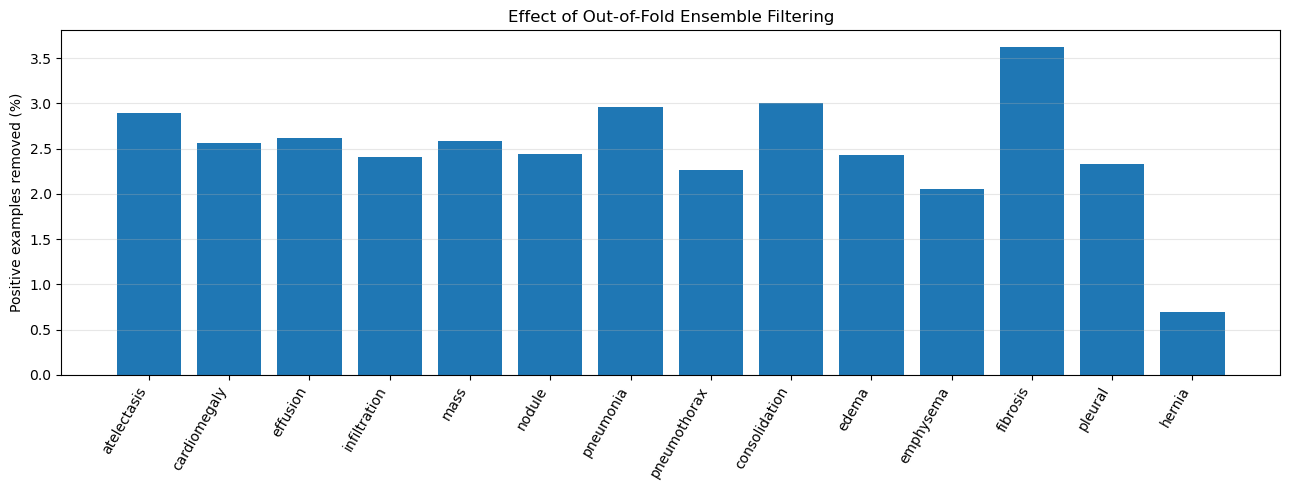

In [35]:
plt.figure(figsize=(13, 5))

plt.bar(removal_df["Class"], removal_df["Removed (%)"])

plt.ylabel("Positive examples removed (%)")
plt.title("Effect of Out-of-Fold Ensemble Filtering")
plt.xticks(rotation=60, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [37]:
removed_labels = train_labels[remove_mask]

print("Total images removed:", remove_mask.sum())
print("Average positive labels per removed image:", removed_labels.sum(axis=1).mean())
print("Average positive labels per retained image:", train_labels[~remove_mask].sum(axis=1).mean())
print(f"Training images removed: {100 * remove_mask.mean():.2f}%")

Total images removed: 843
Average positive labels per removed image: 1.723606168446026
Average positive labels per retained image: 0.7091400966183575
Training images removed: 1.07%


In [38]:
label_counts = train_labels.sum(axis=1)
comparison_df = pd.DataFrame({"Positive Labels": label_counts,"Rejected": remove_mask})

distribution = pd.crosstab(comparison_df["Positive Labels"], comparison_df["Rejected"], normalize="columns") * 100
distribution.columns = ["Retained (%)", "Rejected (%)"]
display(distribution.round(2))

,Retained (%),Rejected (%)
Positive Labels,,
0,54.63,0.00
1,27.30,49.11
2,12.46,35.11
3,4.23,11.27
4,1.03,3.32
5,0.27,1.19
6,0.06,0.00
7,0.02,0.00
8,0.00,0.00


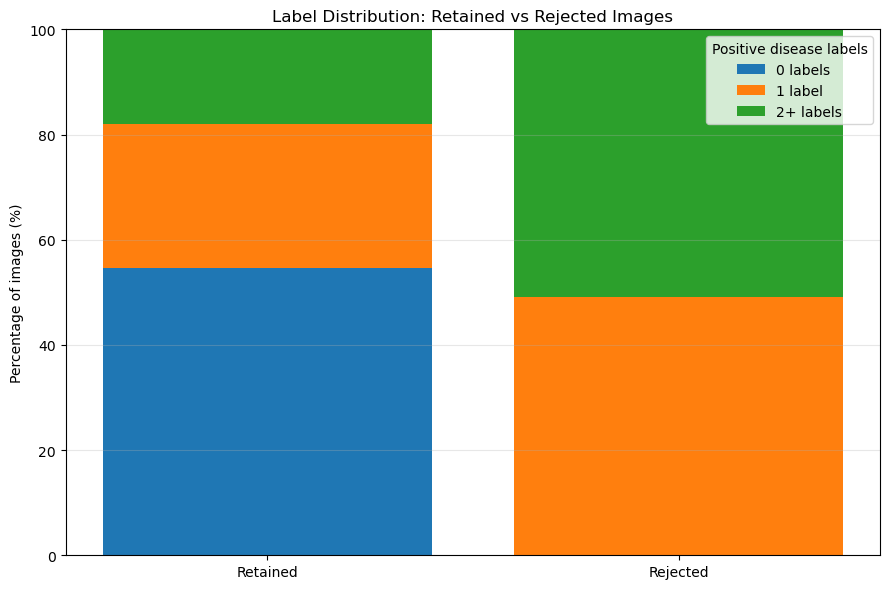

In [39]:
label_counts = train_labels.sum(axis=1)

categories = {
    "0 labels": label_counts == 0,
    "1 label": label_counts == 1,
    "2+ labels": label_counts >= 2
}

retained = ~remove_mask
rejected = remove_mask

groups_to_plot = [retained, rejected]
group_names = ["Retained", "Rejected"]

bottom = np.zeros(2)

plt.figure(figsize=(9, 6))

for category, mask in categories.items():
    percentages = [
        100 * np.mean(mask[group])
        for group in groups_to_plot
    ]

    plt.bar(
        group_names,
        percentages,
        bottom=bottom,
        label=category
    )

    bottom += percentages

plt.ylabel("Percentage of images (%)")
plt.title("Label Distribution: Retained vs Rejected Images")
plt.ylim(0, 100)
plt.legend(title="Positive disease labels")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
np.save("rejection_mask.npy", remove_mask)

keep_indices = np.flatnonzero(~remove_mask)
filtered_train = Subset(train_df, keep_indices)
filtered_loader = DataLoader(filtered_train, batch_size=64, shuffle=True)

print("Original:", len(train_df))
print("Filtered:", len(filtered_train))

Original: 78468
Filtered: 77625


In [41]:
ensemble_probs = (oof_probs_1 + oof_probs_2) / 2

print(ensemble_probs.shape)

(78468, 14)


In [ ]:
percentiles = [5, 10, 15, 20, 25]

results = []

for percentile in percentiles:
    thresholds = np.zeros(14)

    for i in range(14):
        positive = train_labels[:, i] == 1
        thresholds[i] = np.percentile(ensemble_probs[positive, i], percentile)

    low_confidence = ((ensemble_probs <= thresholds) & (train_labels == 1))
    rejected = low_confidence.any(axis=1)
    results.append({"Percentile": percentile, "Images Removed": rejected.sum(), "Removed (%)": rejected.mean() * 100})

sweep_df = pd.DataFrame(results)
display(sweep_df)

,Percentile,Images Removed,Removed (%)
0,5,2594,3.305806
1,10,5068,6.458684
2,15,7473,9.523627
3,20,9781,12.464954
4,25,12036,15.338737


In [46]:
thresholds = np.array([np.percentile(ensemble_probs[train_labels[:, i] == 1, i], 25) for i in range(14)])
remove_mask = (((ensemble_probs <= thresholds) & (train_labels == 1)).any(axis=1))
print("Rejected:", remove_mask.sum())

Rejected: 12036


In [47]:
before = train_labels.sum(axis=0)
after = train_labels[~remove_mask].sum(axis=0)

rejection_df = pd.DataFrame({"Class": class_names, "Before": before, "After": after, "Removed": before - after, "Removed (%)": 100 * (before - after) / before})

display(rejection_df.round(2))

,Class,Before,After,Removed,Removed (%)
0,atelectasis,7996,5057,2939,36.76
1,cardiomegaly,1950,1179,771,39.54
2,effusion,9261,6226,3035,32.77
3,infiltration,13914,9090,4824,34.67
4,mass,3988,2526,1462,36.66
5,nodule,4375,2656,1719,39.29
6,pneumonia,978,609,369,37.73
7,pneumothorax,3705,2463,1242,33.52
8,consolidation,3263,2135,1128,34.57
9,edema,1690,1147,543,32.13


/tmp/ipykernel_117966/395683828.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


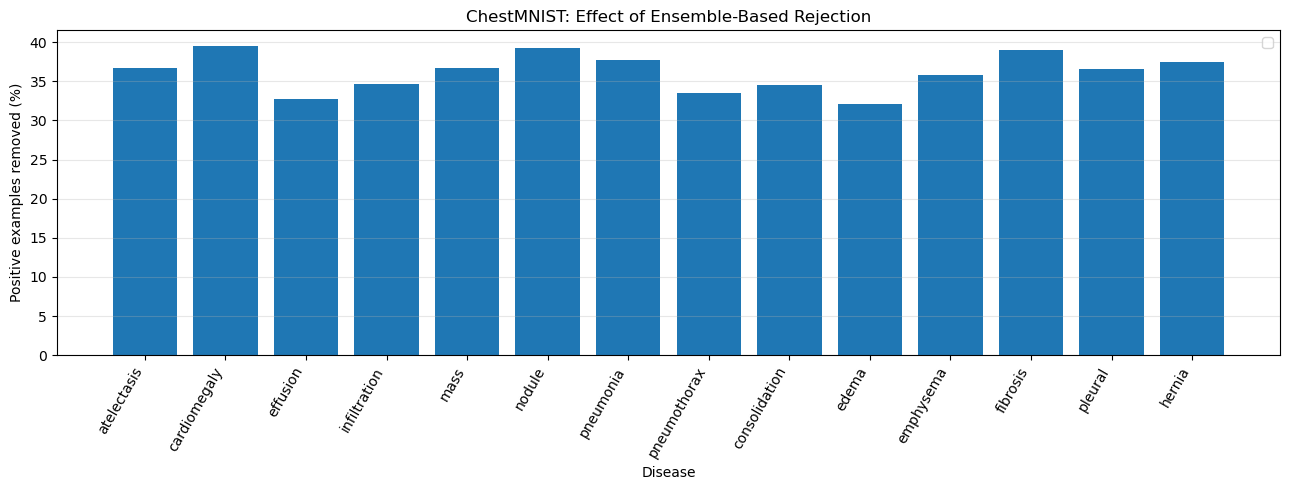

In [49]:
plt.figure(figsize=(13, 5))
plt.bar(rejection_df["Class"], rejection_df["Removed (%)"])
plt.xlabel("Disease")
plt.ylabel("Positive examples removed (%)")
plt.title("ChestMNIST: Effect of Ensemble-Based Rejection")
plt.xticks(rotation=60, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
keep_indices = np.flatnonzero(~remove_mask)
rejected_indices = np.flatnonzero(remove_mask)

np.save("rejection_mask_25.npy", remove_mask)
np.save("retained_indices_25.npy", keep_indices)
np.save("rejected_indices_25.npy", rejected_indices)

print("Rejected:", len(rejected_indices))
print("Retained:", len(keep_indices))